# Linear Regression — Exercise

**Dataset:** Rental apartments in Zurich: area, rooms and monthly rent.

Read [linear_regression_concept.ipynb](linear_regression_concept.ipynb) first. Run cells from top to bottom. Data preparation and plotting code are provided. Replace each `None` marked with a `# TODO` comment with the expression requested above the cell. These cells are incomplete until you fill the gap. Answer interpretation questions in one or two sentences. Check your work with [linear_regression_solution.ipynb](linear_regression_solution.ipynb).

## Libraries and settings

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
import statsmodels.api as sm
import statsmodels.formula.api as smf

## 1. Calculate OLS with three apartments

The OLS formula is in the concept notebook. Replace the gap with `np.sum((x - x_mean) * (y - y_mean))`. The remaining calculation is provided. What are the slope and intercept? Is the 95 m² prediction interpolation or extrapolation for these three flats?

In [13]:
x = np.array([40, 60, 80])
y = np.array([1200, 1600, 2000])
x_mean = x.mean()
y_mean = y.mean()
# TODO: Replace None with the expression requested above.
numerator = np.sum((x - x_mean) * (y - y_mean))
denominator = np.sum((x - x_mean) ** 2)
slope = numerator / denominator
intercept = y_mean - slope * x_mean
print('Slope:', slope, 'Intercept:', intercept)
print('Predicted rent for 95 m²:', intercept + slope * 95)
# A separate R² illustration:
print('R² for SSE=20 and SST=100:', 1 - 20 / 100)

Slope: 20.0 Intercept: 400.0
Predicted rent for 95 m²: 2300.0
R² for SSE=20 and SST=100: 0.8


> ✏️ **Your interpretation**
>
Es ist Extrapolation, da der Wert x=95 ausserhalb des gegebenen Werteraumes [40-80] liegt.

## 2. Load apartments

Preparation is provided. What does a point in this plot represent? Describe the overall pattern.

        area  rooms   price
count  571.0  571.0   571.0
mean    86.9    3.4  2454.2
std     34.8    1.2   797.2
min     15.0    1.0  1005.0
25%     63.0    2.5  1831.5
50%     86.0    3.5  2345.0
75%    105.0    4.5  2950.0
max    270.0    7.5  4960.0


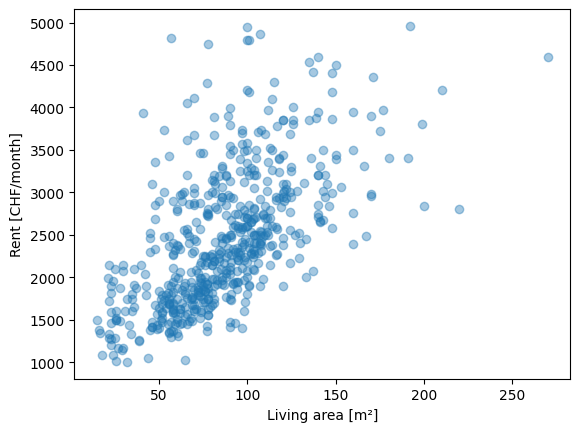

In [14]:
apt = pd.read_csv('../00_Data/rental_apartments_canton_zh.csv', sep=';')
apt = apt[['bfs_name', 'rooms', 'area', 'price']].dropna().drop_duplicates()
apt = apt[(apt['price'] >= 1000) & (apt['price'] <= 5000)]
train, test = train_test_split(apt, test_size=0.2, random_state=42)
print(train[['area', 'rooms', 'price']].describe().round(1))
plt.scatter(train['area'], train['price'], alpha=0.4) # alpha beschreibt die Transparenz der Punkte im Scatterplot.
plt.xlabel('Living area [m²]')
plt.ylabel('Rent [CHF/month]')
plt.show()

> ✏️ **Your interpretation**

Die Grafik beschreibt den Mietpreis mit der zugehörigen Wohnfläche.

## 3. Fit simple OLS

Replace the gap with `smf.ols("price ~ area", data=train).fit()`. Interpret the printed area coefficient.

Intercept    1248.20
area           13.87
dtype: float64
Training R²: 0.368


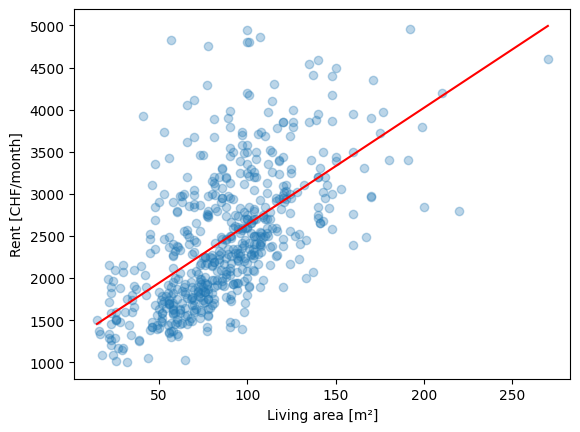

In [15]:
# TODO: Replace None with the expression requested above.
simple = smf.ols("price ~ area", data=train).fit() # erstellt und trainiert ein einfaches lineares Regressionsmodell, das den Mietpreis (price) anhand der Wohnfläche (area) in den Trainingsdaten (train) vorhersagt.
print(simple.params.round(2))
print('Training R²:', round(simple.rsquared, 3))
grid = pd.DataFrame({'area': np.linspace(train['area'].min(), train['area'].max(), 100)})
# Dieser Code erstellt einen neuen Pandas-DataFrame namens grid.
# train['area'] greift auf die Spalte area der Trainingsdaten zu.
# .min() ermittelt die kleinste Fläche.
# .max() ermittelt die größte Fläche.
# np.linspace(..., 100) erzeugt 100 gleichmäßig verteilte Werte zwischen der kleinsten und größten Fläche.
# 'area' benennt die DataFrame-Spalte.
# pd.DataFrame(...) erstellt daraus einen DataFrame.
plt.scatter(train['area'], train['price'], alpha=0.3)
plt.plot(grid['area'], simple.predict(grid), color='red') # grid liefert die möglichen Wohnflächen, und simple.predict(grid) liefert die dazugehörigen vorhergesagten Mietpreise.
plt.xlabel('Living area [m²]')
plt.ylabel('Rent [CHF/month]')
plt.show()

**Answer:** Die angepasste Geradenformel lautet: Miete = 1248,20 + 13,87 · Fläche.

- Jeder zusätzliche m² entspricht im Durchschnitt einer um 13,87 CHF/Monat höheren prognostizierten Miete.
- Beispiel: Eine 100 m² große Wohnung ergibt 1248,20 + 1387 = 2635 CHF/Monat; eine 50 m² große Wohnung ergibt 1248,20 + 693,50 = 1942 CHF/Monat.
- Der Achsenabschnitt von 1'248,20 CHF ist die Prognose bei 0 m². Er dient lediglich zur Einordnung der Geraden; es handelt sich nicht um eine realistische Miete.
- R² des Trainingsmodells = 0,368: Die Wohnfläche erklärt etwa 37 % der Schwankungen bei den Mieten. Die übrigen 63 % sind auf die Lage, den Zustand und andere Faktoren zurückzuführen, die nicht im Modell berücksichtigt sind.

## 4. Read intervals for 95 m²

Which columns describe average rent? Which interval concerns one new apartment?

In [20]:
new_flat = pd.DataFrame({'area': [95]})
intervals = simple.get_prediction(new_flat).summary_frame(alpha=0.05)
print(intervals[['mean', 'mean_ci_lower', 'mean_ci_upper',
                 'obs_ci_lower', 'obs_ci_upper']].round(0))

# Gibt den durchschnittlichen Mietpreis, die Grenzen des Konfidenzintervalls (CI = Vorhersage für den Durchschnitt)
# und die Grenzen des Vorhersageintervalls (PI = Vorhersage für eine neue Vorhersage) als gerundete Werte aus.

     mean  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  2566.0         2513.0         2620.0        1319.0        3814.0


> ✏️ **Your interpretation**

Der Wert von `mean`,`mean_ci_lower`,`mean_ci_upper` beschreibt die durchschnittliche Miete mit den Grenzen des Konfidenzintervalls, die `obs_ci_lower` und `obs_ci_upper` beschreiben die Vorhersage für das neue Appartement.

## 5. Add rooms

Replace the gap with `smf.ols("price ~ area + rooms", data=train).fit()`. What does the area coefficient now mean?

In [18]:
# TODO: Replace None with the expression requested above.
multiple = smf.ols("price ~ area + rooms", data=train).fit() # price = Zielvariable, Einflussvariablen = area, rooms
print(multiple.params.round(2))
print('Training R²:', round(multiple.rsquared, 3))
print('Input correlations:')
print(train[['area', 'rooms']].corr().round(2))

Intercept    1294.87
area           15.48
rooms         -54.42
dtype: float64
Training R²: 0.369
Input correlations:
       area  rooms
area   1.00   0.86
rooms  0.86   1.00


**Answer**
Der Preis einer Wohnung berechnet sich aus: Preis = 1294.87 + 15.48 * Wohnfläche - 54.42 * Anzahl Räume.

Es besteht eine positive lineare Beziehung zwischen der Wohnfläche und der Anzahl Räume, dies beschreibt jedoch keinen kausalen Zusammenhang.

## 6. Check residuals

Do you see a curve or a funnel in the residual plot? Can the Q–Q plot establish independence?

Sehen Sie im Residuenplot eine Kurve oder einen Trichter? Lässt sich anhand des Q–Q-Plots die Unabhängigkeit nachweisen?

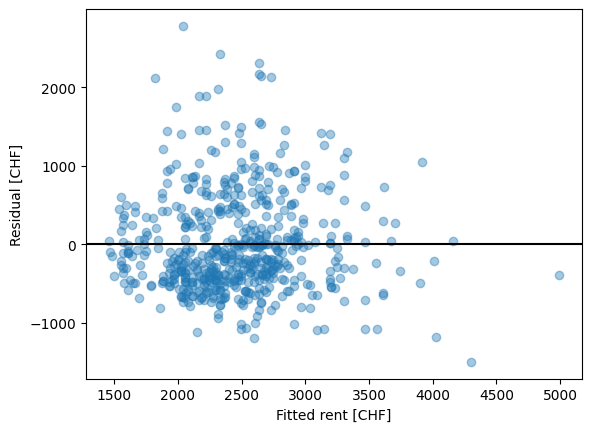

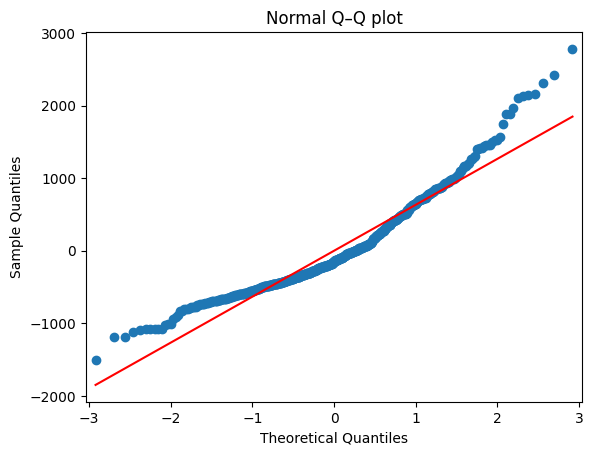

In [21]:
plt.scatter(simple.fittedvalues, simple.resid, alpha=0.4)  # Zeigt Vorhersagen (simple.fittedvalues) gegen Fehler (simple.resid) mit transparenter Darstellung.
plt.axhline(0, color='black') # Linie bei y=0
plt.xlabel('Fitted rent [CHF]')
plt.ylabel('Residual [CHF]')
plt.show()

sm.qqplot(simple.resid, line='s')
plt.title('Normal Q–Q plot')
plt.show()

**Answer**

- **Kurve:** Die Residuen streuen um den Wert 0, ohne dass sich eine deutliche Krümmung abzeichnet; daher lässt sich der durchschnittliche Trend recht gut durch eine Gerade beschreiben.
- **Trichter:** Die vertikale Streuung ist über die gesamten angepassten Mieten hinweg in etwa gleich (etwa −1500 bis +2800 CHF), sodass kein ausgeprägter Trichter vorliegt.
- **Schiefe:** Die Residuen sind nicht symmetrisch. Positive Residuen erreichen etwa +2800 CHF, während negative bei etwa −1500 CHF enden. Einige Wohnungen sind deutlich teurer, als es ihre Lage vermuten lässt, aber nur wenige sind deutlich günstiger. Der Mietfilter von 1000–5000 CHF schneidet zudem die Extreme ab.
- **Q–Q-Diagramm:** Beide Enden der Kurve liegen oberhalb der roten Linie, was diese rechtsschiefe Verteilung bestätigt: Die Fehler sind nicht normalverteilt.
- **Unabhängigkeit:** Das Q–Q-Diagramm kann keine Unabhängigkeit nachweisen. Die Unabhängigkeit muss anhand des Studiendesigns beurteilt werden; so können beispielsweise Wohnungen in derselben Gemeinde oder im selben Gebäude ähnlich sein.

## 7. Final test evaluation

These two models are fixed before this test comparison. Which has lower RMSE? What does RMSE of 500 CHF mean? Use CV for further model choices, rather than repeated test comparisons.

Diese beiden Modelle wurden vor diesem Testvergleich festgelegt. Welches weist den geringeren RMSE auf? Was bedeutet ein RMSE von 500 CHF? Verwenden Sie für die weitere Modellauswahl Cross-Validation (CV) anstelle wiederholter Testvergleiche.

In [22]:
simple_pred = simple.predict(test)
multiple_pred = multiple.predict(test)
print('Simple test RMSE:', round(np.sqrt(mean_squared_error(test['price'], simple_pred)), 1))
print('Multiple test RMSE:', round(np.sqrt(mean_squared_error(test['price'], multiple_pred)), 1))
print('Simple test R²:', round(r2_score(test['price'], simple_pred), 3))
print('Multiple test R²:', round(r2_score(test['price'], multiple_pred), 3))

Simple test RMSE: 705.5
Multiple test RMSE: 710.3
Simple test R²: 0.312
Multiple test R²: 0.302


**Answer**

Das simple-Modell weist den geringeren RMSE auf (705.5), das multiple-Modell mit einem Parameter mehr hat bei den Testdaten nicht geholfen. RMSE von 500 CHF bedeutet die durchschnittlichen Prognosefehler.

### Jupyter notebook — footer info

Include this information when submitting your notebook.

In [ ]:
import platform
from datetime import datetime
print(platform.platform())
print("Python:", platform.python_version())
print("Date:", datetime.now().isoformat(timespec="seconds"))